## Naïve Bayes classifiers

- A probabilistic classifier based on Bayes' Theorem with the assumption of feature independence.
- Trade-off: Faster training but slightly worse generalization than LogisticRegression & LinearSVC.  
- Efficiency: Learns parameters per feature individually, using simple per-class statistics.  
- Types in scikit-learn:  
  - GaussianNB: For continuous data.  
  - BernoulliNB: For binary data.  
  - MultinomialNB: For count-based data (e.g., word frequency in text).  
- Usage: text classification, spam filtering, and sentiment analysis

**Algorithm**

- Input: Dataset $D$ with features $X = \{X_1, X_2, ..., X_n\}$ and class labels $Y$.  
- Calculate the prior probability of each class:  
$$
P(C_k) = \frac{\text{Count of samples in } C_k}{\text{Total number of samples}}
$$  
- For each feature $X_i$ given class $C_k$, compute the conditional probability $P(X_i | C_k)$  
- Compute the posterior probability for each class:  
$$
P(C_k | X) = \frac{P(X | C_k) P(C_k)}{P(X)}
$$  
- Make decision: Assign $X$ to the class $C_k$ with the *highest posterior probability*
$$
\hat{Y} = \arg\max_{C_k} P(C_k) \prod_{i} P(X_i | C_k)
$$  

Critical assumption:  Features $X_i$ are conditionally independent given the class $C_k$ (often doesn't hold in real-world datasets):  
$$
P(X_1, X_2, ..., X_n | C_k) = P(X_1 | C_k) P(X_2 | C_k) ... P(X_n | C_k)
$$  

### Example: classifying emails as Spam or Non-Spam

- Data

| Email | Contains Free? | Contains Win? | Spam |
| ----- | -------------- | ------------- | ---- |
| E1    | Yes            | Yes           | Yes  |
| E2    | No             | Yes           | No   |
| E3    | Yes            | No            | No   |
| E4    | Yes            | Yes           | Yes  |

- **Question: If a new email contains both Free and Win, is it spam?**

- **Calculate prior probabilities**

$$
P(\text{S}) =  \frac{2}{4} = 0.5, 
P(\text{NS}) =  \frac{2}{4} = 0.5
$$


- **Calculate likelihood** $P(\text{Feature} | \text{Class})$ for each feature:

$$
P(\text{Free} | \text{S}) = \frac{\text{Spam emails with `Free'}}{\text{Total S Emails}} = \frac{2}{2} = 1.0
$$

$$
P(\text{Free} | \text{NS}) = \frac{1}{2} = 0.5
$$

$$
P(\text{Win} | \text{S}) = \frac{2}{2} = 1.0
$$

$$
P(\text{Win} | \text{NS}) = \frac{1}{2} = 0.5
$$

- **Calculate posterior probabilities using Naïve Bayes**

$$
P(\text{S} | \text{Free, Win}) \propto P(\text{S}) \times P(\text{Free} | \text{S}) \times P(\text{Win} | \text{S})= 0.5 \times 1.0 \times 1.0 = 0.5
$$

$$
P(\text{NS} | \text{Free, Win}) \propto P(\text{NS}) \times P(\text{Free} | \text{NS}) \times P(\text{Win} | \text{NS}) = 0.5 \times 0.5 \times 0.5 = 0.125
$$


- **Decision**: Since $P(\text{S} | \text{Free, Win})>P(\text{NS} | \text{Free, Win})$,  it's a spam email.

See also:

- [StatQuest's video](https://www.youtube.com/watch?v=O2L2Uv9pdDA)

In [1]:
# code adapted from https://scikit-learn.org/stable/modules/naive_bayes.html#naive-bayes. Please check it for details regarding implementations and parameters that you can tune.

from sklearn.naive_bayes import GaussianNB

X, y = datasets.load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)
gnb = GaussianNB()
y_pred = gnb.fit(X_train, y_train).predict(X_test)
print(
    "Number of mislabeled points out of a total %d points : %d"
    % (X_test.shape[0], (y_test != y_pred).sum())
)

NameError: name 'datasets' is not defined

## Decision Trees

- A hierarchy of if–else questions, represented by tree nodes and branches, that lead to a decision, or tree leaves. It's used for modeling classification and regression.
- Each root node represents an input variable and it's split point.
- Leaf nodes represent class labels and branches represent conjunctions of features leading to those labels.

### CART (Classification and Regression Trees)

#### Greedy Recursive Binary Splitting

- Divides the input space.
- Evaluates all input variables and split points to select the one with the lowest cost.
- cost function:
    - Regression: Sum of squared errors
    - Classification: Gini index (measures purity of leaf nodes)

##### Gini Index

- Measures "how mixed the data in a node is".
- A measure of how often a randomly chosen element of a set would be incorrectly labeled if it were labeled randomly and independently according to the distribution of labels in the set. 
- It becomes 0 when all cases in the node fall into a single target category.
- Consider a set of items has $J$ classes and relative frequencies $p_1, \cdots, p_J$ and the probability of miscategorizing that item is $\sum_{k \ne i} p_k = 1-p_i$. Then Gini index:

$$
{\rm I}_G(p) = \sum_{i=1}^J \left( p_i \sum_{k\neq i} p_k \right)
 = \sum_{i=1}^J p_i (1-p_i)
 = 1 - \sum^J_{i=1} p_i^2.
 $$
(see [wiki](https://en.wikipedia.org/wiki/Decision_tree_learning) and [this notes](https://www3.cs.stonybrook.edu/~cse352/L10basicDTalgorithm.pdf) for a broader discussion)

#### Pruning

- Stop the creation of the  tree early (pre-pruning)
- Remove nodes that contain little information (pruning)
- These prevent overfitting by controlling specificity to training data.
- Simpler trees are easier to interpret and generalize better. 

### Advantages

easily visualized and understood (interpretable). Also they work well with features having different scales, or a mix of binary and continuous features.


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Accuracy on training set = 0.9583333333333334
Accuracy on test set: 0.9666666666666667
Feature importance: [0.         0.         0.54339627 0.45660373]


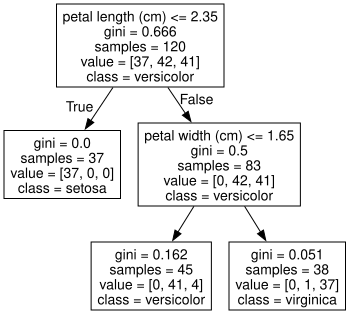

In [ ]:
# code adapted from https://scikit-learn.org/stable/modules/tree.html#classification

from sklearn import tree
import graphviz

iris = datasets.load_iris()
X, y = iris.data, iris.target
clf = tree.DecisionTreeClassifier(
    max_depth=2
)  # (max_depth=3) # max depth and complexity (overfitting)
clf = clf.fit(X, y)
clf.fit(X_train, y_train)
print(f"Accuracy on training set = {clf.score(X_train, y_train)}")
print(f"Accuracy on test set: {clf.score(X_test, y_test)}")
print(f"Feature importance: {clf.feature_importances_}")
# "if a feature has a low feature_importance, it doesn’t mean that this feature  is uninformative. It only means that the feature was not picked by the tree, likely  because another feature encodes the same information." (Guido & Müller)
dot_data = tree.export_graphviz(
    clf, out_file=None, feature_names=iris.feature_names, class_names=iris.target_names
)
graph = graphviz.Source(dot_data)
graph

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

<Figure size 640x480 with 0 Axes>

Text(0.5, 0, 'data')

Text(0, 0.5, 'target')

Text(0.5, 1.0, 'Decision Tree Regression')

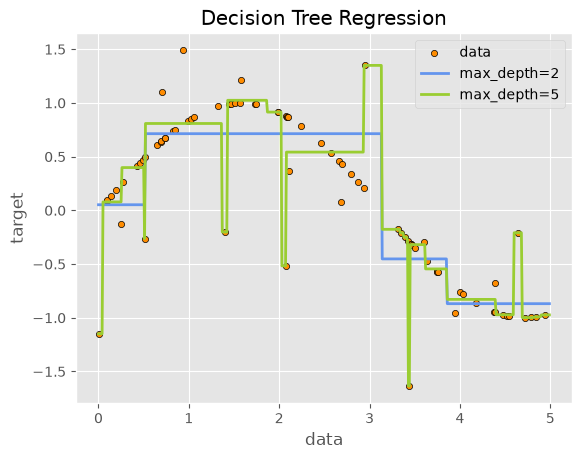

In [ ]:
# A regression example
# code adapted from https://scikit-learn.org/stable/auto_examples/tree/plot_tree_regression.html

from sklearn.tree import DecisionTreeRegressor

rng = np.random.RandomState(1)
X = np.sort(5 * rng.rand(80, 1), axis=0)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(16))

regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)

plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.plot(X_test, y_2, color="yellowgreen", label="max_depth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()

## Uncertainty estimates from classifiers

- Classifier predictions often require understanding not just the predicted class but also the certainty of the prediction.  
- Different mistakes (false positives vs. false negatives) have varying real-world consequences.  
  - Example: In medical testing for cancer:  
    - A false positive leads to additional tests.  
    - A false negative means a serious disease might go untreated.  
- Scikit-learn provides two functions to estimate uncertainty in classifiers:  
  - `decision_function`  
  - `predict_proba`  
- Most classifiers support at least one of these functions, and many support both.  

### Very important

Please read [this page](https://scikit-learn.org/stable/modules/calibration.html) from scikit-learn regarding uncertainty quantification


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# let's take the example of logistic regression which we discussed above

iris = datasets.load_iris()

# first 100 samples (0 = Setosa, 1 = Versicolor)
X = iris.data[:100, :2]
y = iris.target[:100]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Accuracy: 0.95


## Decision function

The values of decision function encode how strongly the model `believes' a data point to belong to the  “positive” class, in this case class 1. Positive values indicate a preference for the positive class, and negative values indicate a preference for the “negative” (other) class. (Guido & Mueller)


Decision function:
 [ 5.01399674 -4.00641672 -4.36799334  7.44675926 -2.78794936 -2.42011444
 -1.93314472 -1.32286799  1.47981556  4.15919209  0.74205962 -2.78586326
 -5.4631537  -0.83798436  1.72225737  4.280413   -4.24885853 -4.36799334
 -3.88102362 -2.05436562]
[1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0]


Text(0, 0.5, 'Decision function')

Binary decision function:
 [ True False False  True False False False False  True  True  True False
 False False  True  True False False False False]
Predictions:
 [1 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0]
Actual:
 [1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0]


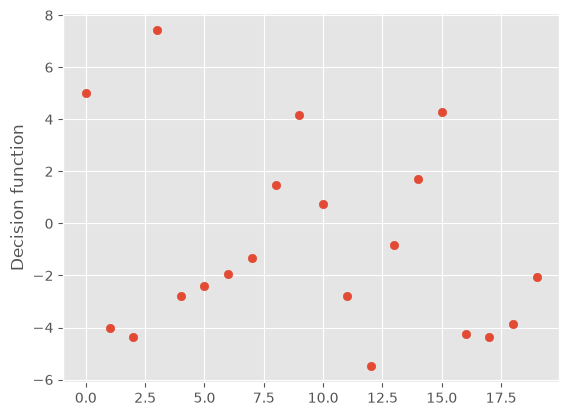

In [ ]:
print(f"Decision function:\n {model.decision_function(X_test)}")
print(y_test)
plt.scatter(np.arange(0, len(model.predict(X_test))), model.decision_function(X_test))
plt.ylabel("Decision function")
print(f"Binary decision function:\n {model.decision_function(X_test) > 0}")
print(f"Predictions:\n {model.predict(X_test)}")
print(f"Actual:\n {y_test}")
pass

### predicted probabilities

- The output of `predict_proba` is a probability for each class.
- Probabilities for the two classes in classification always sum to 1.  
- The class with a probability above 50% is the one that is predicted.  
- In practice, classifiers are usually relatively certain about their predictions for most points.  
- The accuracy of uncertainty estimates depends on the model and its parameters:  
  - Overfitted models: Tend to make overly certain predictions, even when incorrect.  
  - Simpler models: Often show greater uncertainty in their predictions.  
- A model is considered calibrated if its reported uncertainty matches its actual accuracy:  
  - For example, a prediction with 70% certainty is correct 70% of the time.  

First few predicted probabilities:
[[0.00660044 0.99339956]
 [0.98212678 0.01787322]
 [0.98748203 0.01251797]]


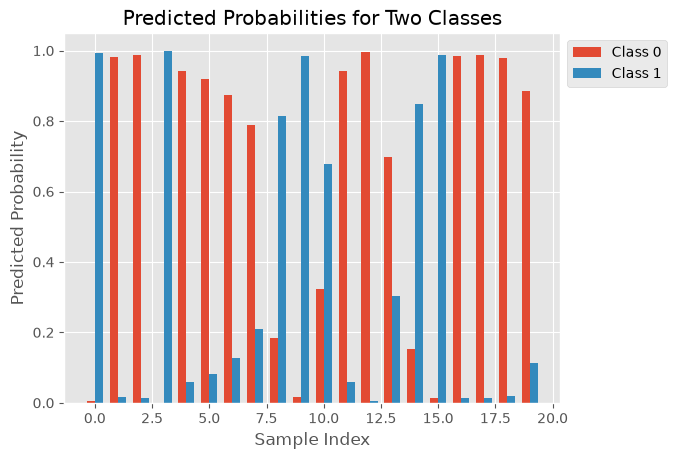

In [ ]:
probabilities = model.predict_proba(X_test)
print(f"First few predicted probabilities:\n{probabilities[:3]}")

# plot them

x = np.arange(len(probabilities))
width = 0.35
plt.bar(x - width / 2, probabilities[:, 0], width, label="Class 0")
plt.bar(x + width / 2, probabilities[:, 1], width, label="Class 1")

# Add labels, title, and legend
plt.xlabel("Sample Index")
plt.ylabel("Predicted Probability")
plt.title("Predicted Probabilities for Two Classes")
# plt.xticks(x)
plt.legend(bbox_to_anchor=[1, 1])
pass;

In [ ]:
# this can be extended to multiclass classifications. the code works as expected

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# let's take the example of logistic regression which we discussed above

iris = datasets.load_iris()

X = iris.data  # [:100, :2]
y = iris.target  # [:100]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print(f"First few decision function:\n {model.decision_function(X_test[:3])}")

probabilities = model.predict_proba(X_test)
print(f"First few predicted probabilities:\n{probabilities[:3]}")

pass;

Accuracy: 1.00
First few decision function:
 [[-7.6536117   1.76821981  5.88539188]
 [-1.58337136  1.93907857 -0.35570721]
 [-5.45707804  1.24869262  4.20838542]]
First few predicted probabilities:
[[1.29737946e-06 1.60293700e-02 9.83969333e-01]
 [2.61229287e-02 8.84713053e-01 8.91640180e-02]
 [6.03071508e-05 4.92774253e-02 9.50662268e-01]]
